# NuAncestor Multi-Orbit Visibility and Scheduling Analysis

This notebook automatically detects every `Results_aXXX_iYYY` folder in the selected base path and extracts the semi-major axis and inclination from each folder name.

For every orbit, it compares invalid nights and total nighttime contact across the five visibility telescopes and evaluates how invalid nights and valid nighttime contact change with the minimum valid-contact requirement. It also evaluates smart 2-Telescope Scheduling and 3-Telescope Scheduling for Chile and Hawaii, including scheduling sensitivity to the observation duration.

2-Telescope Scheduling considers only the fixed pair selected for each region. The third telescope is excluded from the nighttime windows, scheduling decisions, cadence constraints and summary counts. A regional night is valid when neither selected telescope exceeds its consecutive missed-night allowance.

3-Telescope Scheduling considers all three regional telescopes. A regional night is valid when none of the three exceeds its consecutive missed-night allowance.

Finally, the notebook ranks every orbit using the individual performance criteria and their summed ranks. Fewer invalid nights and higher nighttime contact times rank better. Both unweighted and weighted rankings are provided.

Version 10/2026 by Pedro de S. C. Leonardo

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

from itertools import combinations, permutations
from matplotlib.ticker import MaxNLocator
from pathlib import Path
from IPython.display import display

In [2]:
# Main folder containing all Results_aXXX_iYYY simulation folders
BASE = Path("All_Results/PerfectingSMA")

# Settings to change !!
MULTIPLE_INCLINATIONS = False
DAYS = 365
CURRENT_CONTACT_REQUIREMENT_MIN = 30
VISIBILITY_CONTACT_REQUIREMENTS_MIN = [100, 90, 80, 70, 60, 50, 45, 40, 30, 28, 25, 22, 20, 18, 15]
SCHEDULING_CONTACT_REQUIREMENTS_MIN = [30, 28, 25, 22, 20, 18, 15]
MAX_CONSECUTIVE_MISSED_NIGHTS = 1  # Every-other-night requirement

# Conservative setting: regional telescope slots cannot overlap
ALLOW_SIMULTANEOUS_OBSERVATIONS = False
COMMON_NIGHT_MODE = "intersection"  # "intersection" or "union"
EXCLUDE_PARTIAL_EDGE_NIGHTS = True

# FreeFlyer output handling
TIME_MATCH_TOLERANCE_S = 1.0
GAP_FACTOR = 1.5  # A larger gap breaks a continuous interval

SAVE_FIGURES = False
SAVE_TABLES = False

# InContact.txt and IsNight.txt column order:
# time, Chile, LaPalma, Hawaii, SALT, DAG, HARPS, CORALIE,
# ESPRESSO, KPF, HIRES, MAROONX
VISIBILITY_TELESCOPES = ["Chile", "La Palma", "Hawaii", "SALT", "DAG"]
VISIBILITY_COLUMNS = {"Chile": 1, "La Palma": 2, "Hawaii": 3, "SALT": 4, "DAG": 5}
VISIBILITY_COLORS = {"Chile": "r", "La Palma": "blueviolet", "Hawaii": "cyan", "SALT": "orange", "DAG": "lime"}

REGIONAL_TELESCOPES = {
    "Chile": {"names": ["HARPS", "CORALIE", "ESPRESSO"], "columns": [6, 7, 8]},
    "Hawaii": {"names": ["KPF", "HIRES", "MAROONX"], "columns": [9, 10, 11]}}

RESULT_PATTERN = re.compile(r"^Results_a(?P<semi_major_axis>\d+)_i(?P<inclination>-?\d+)$")
detected_cases = []

for folder in BASE.iterdir():
    if not folder.is_dir():
        continue

    match = RESULT_PATTERN.fullmatch(folder.name)

    if match is None:
        continue

    semi_major_axis = int(match.group("semi_major_axis"))
    inclination = int(match.group("inclination"))
    detected_cases.append({
        "name": f"a = {semi_major_axis:,} km, i = {inclination}°",
        "semi_major_axis": semi_major_axis,
        "inclination": inclination,
        "folder": folder.name})

CASES = sorted(detected_cases, key=lambda case: (case["semi_major_axis"], case["inclination"]))

if not CASES:
    raise FileNotFoundError(f"No Results_aXXX_iYYY folders were found in {BASE}.")

detected_inclinations = sorted({case["inclination"] for case in CASES})
detected_multiple_inclinations = len(detected_inclinations) > 1

if MULTIPLE_INCLINATIONS != detected_multiple_inclinations:
    raise ValueError(
        f"MULTIPLE_INCLINATIONS is {MULTIPLE_INCLINATIONS}, but the detected inclinations are "
        f"{detected_inclinations}. Set MULTIPLE_INCLINATIONS to {detected_multiple_inclinations}.")

if CURRENT_CONTACT_REQUIREMENT_MIN not in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_CONTACT_REQUIREMENT_MIN must be included in VISIBILITY_CONTACT_REQUIREMENTS_MIN.")

if CURRENT_CONTACT_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_CONTACT_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

single_inclination = detected_inclinations[0] if not MULTIPLE_INCLINATIONS else None


def orbit_label(case):
    """Return the orbit label used in plot legends and on plot axes."""
    if MULTIPLE_INCLINATIONS:
        return f"a = {case['semi_major_axis']:,} km, i = {case['inclination']}°"

    return f"a = {case['semi_major_axis']:,} km"


def plot_title(title):
    """Add the inclination to plot titles only for a single-inclination analysis."""
    if MULTIPLE_INCLINATIONS:
        return title

    return f"{title}, i = {single_inclination}°"


def save_figure(fig, filename):
    """Save one analysis figure when requested."""
    if not SAVE_FIGURES:
        return

    output = BASE / "analysis_plots"
    output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output / filename, dpi=300, bbox_inches="tight")


print(f"Detected {len(CASES)} orbit folders with inclinations {detected_inclinations}.")
display(pd.DataFrame(CASES)[["semi_major_axis", "inclination", "folder"]].rename(columns={
    "semi_major_axis": "Semi-major axis [km]",
    "inclination": "Inclination [deg]",
    "folder": "Folder"}).style.hide(axis="index"))

Detected 16 orbit folders with inclinations [0].


Semi-major axis [km],Inclination [deg],Folder
21390,0,Results_a21390_i0
21480,0,Results_a21480_i0
21800,0,Results_a21800_i0
21850,0,Results_a21850_i0
21900,0,Results_a21900_i0
21930,0,Results_a21930_i0
22000,0,Results_a22000_i0
22300,0,Results_a22300_i0
22400,0,Results_a22400_i0
22500,0,Results_a22500_i0


In [3]:
# Main file loading and interval functions

ALL_STATION_COLUMNS = sorted(
    set(VISIBILITY_COLUMNS.values()) |
    {column for region in REGIONAL_TELESCOPES.values() for column in region["columns"]})


def read_result(folder, filename):
    """Read and clean one FreeFlyer results file."""
    path = BASE / folder / filename

    if not path.exists():
        raise FileNotFoundError(f"Result file not found: {path}")

    data = pd.read_csv(path, skiprows=3, sep=r"\s+", header=None, engine="python", dtype=str)

    # Remove repeated headers or other non-numeric lines
    data = data.apply(pd.to_numeric, errors="coerce").dropna(how="any")

    if data.empty:
        raise ValueError(f"No numeric data were found in {path}.")

    return data.sort_values(0).drop_duplicates(subset=0, keep="last").to_numpy(dtype=float)


def load_case_results(case):
    """Read, align and validate all contact and nighttime results for one orbit."""
    folder = case["folder"]
    contact_data = read_result(folder, "InContact.txt")
    night_data = read_result(folder, "IsNight.txt")
    required_column = max(ALL_STATION_COLUMNS)

    if contact_data.shape[1] <= required_column:
        raise ValueError(
            f"InContact.txt in {folder} must contain columns 0–{required_column}. "
            f"Found {contact_data.shape[1]} columns.")

    if night_data.shape[1] <= required_column:
        raise ValueError(
            f"IsNight.txt in {folder} must contain columns 0–{required_column}. "
            f"Found {night_data.shape[1]} columns.")

    contact = pd.DataFrame({"time": contact_data[:, 0], **{
        f"contact_{column}": contact_data[:, column] for column in ALL_STATION_COLUMNS}})
    night = pd.DataFrame({"time": night_data[:, 0], **{
        f"night_{column}": night_data[:, column] for column in ALL_STATION_COLUMNS}})

    contact = contact[(contact["time"] >= 0) & (contact["time"] < DAYS)]
    night = night[(night["time"] >= 0) & (night["time"] < DAYS)]

    merged = pd.merge_asof(
        contact.sort_values("time"), night.sort_values("time"),
        on="time", direction="nearest", tolerance=TIME_MATCH_TOLERANCE_S / 86400)

    night_columns = [f"night_{column}" for column in ALL_STATION_COLUMNS]
    unmatched = merged[night_columns].isna().any(axis=1)

    if unmatched.any():
        raise ValueError(
            f"{unmatched.sum()} contact rows in {folder} could not be matched to "
            "IsNight.txt within TIME_MATCH_TOLERANCE_S.")

    time = merged["time"].to_numpy()
    visible = merged[[f"contact_{column}" for column in ALL_STATION_COLUMNS]].to_numpy() >= 0.5
    is_night = merged[night_columns].to_numpy() >= 0.5

    if len(time) < 2:
        raise ValueError(f"At least two matched output samples are required in {folder}.")

    if not np.all(np.diff(time) > 0):
        raise ValueError(f"Output times remain non-increasing after cleaning in {folder}.")

    return time, visible, is_night


def infer_time_properties(time):
    """Infer nominal timing without requiring an exactly fixed step."""
    time_steps = np.diff(time)
    nominal_dt = np.median(time_steps)
    simulation_end = min(DAYS, time[-1] + nominal_dt)

    return {"nominal_dt": nominal_dt, "simulation_end": simulation_end}


def get_state_intervals(time, state, simulation_end, nominal_dt):
    """Return continuous True intervals using the actual timestamps."""
    state = np.asarray(state, dtype=bool)
    intervals = []
    start = None
    gap_limit = GAP_FACTOR * nominal_dt

    for i, active in enumerate(state):
        if active and start is None:
            start = time[i]

        if not active:
            continue

        is_last = i == len(state) - 1
        large_gap = not is_last and time[i + 1] - time[i] > gap_limit
        state_ends = not is_last and not state[i + 1]

        if is_last or large_gap or state_ends:
            if is_last:
                end = simulation_end
            elif large_gap:
                end = min(time[i] + nominal_dt, time[i + 1])
            else:
                end = time[i + 1]

            if end > start:
                intervals.append((start, end))

            start = None

    return intervals


def get_complete_nights(time, is_night, simulation_end, nominal_dt):
    """Return complete nighttime intervals."""
    nights = get_state_intervals(time, is_night, simulation_end, nominal_dt)

    if not EXCLUDE_PARTIAL_EDGE_NIGHTS or not nights:
        return nights

    if is_night[0]:
        nights = nights[1:]

    if is_night[-1] and nights:
        nights = nights[:-1]

    return nights


def clip_intervals(intervals, start, end):
    """Clip intervals to a single night."""
    clipped = []

    for interval_start, interval_end in intervals:
        clipped_start = max(interval_start, start)
        clipped_end = min(interval_end, end)

        if clipped_end > clipped_start:
            clipped.append((clipped_start, clipped_end))

    return clipped


def total_interval_hours(intervals):
    """Return the total duration of all intervals in hours."""
    return sum(end - start for start, end in intervals) * 24


def get_invalid_nights(feasible_nights):
    """Return nights violating the every-other-night requirement."""
    invalid_nights = np.zeros(len(feasible_nights), dtype=bool)
    missed_run = 0

    for i, feasible in enumerate(feasible_nights):
        missed_run = 0 if feasible else missed_run + 1
        invalid_nights[i] = missed_run > MAX_CONSECUTIVE_MISSED_NIGHTS

    return invalid_nights

In [4]:
# Visibility analysis functions

def evaluate_visibility_requirement(nights, contact_intervals, min_valid_contact_h):
    """Return invalid nights and valid nighttime contact for one telescope."""
    night_has_valid_contact = np.zeros(len(nights), dtype=bool)
    total_valid_contact_h = 0.0

    for night_index, (night_start, night_end) in enumerate(nights):
        nighttime_contacts = clip_intervals(contact_intervals, night_start, night_end)
        contact_durations_h = np.array([
            (contact_end - contact_start) * 24
            for contact_start, contact_end in nighttime_contacts])
        valid_contacts = contact_durations_h >= min_valid_contact_h - 1e-9

        night_has_valid_contact[night_index] = np.any(valid_contacts)
        total_valid_contact_h += contact_durations_h[valid_contacts].sum()

    invalid_nights = int(get_invalid_nights(night_has_valid_contact).sum())

    return invalid_nights, total_valid_contact_h

In [5]:
# Regional smart scheduling functions

from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix, vstack, csr_matrix

SMART_SOLVER_TIME_LIMIT_S = 120  # Per optimisation stage; None removes the limit

# Select the fixed pair used for 2-Telescope Scheduling
TWO_TELESCOPE_SELECTION = {"Chile": ["HARPS", "CORALIE"], "Hawaii": ["KPF", "HIRES"]}

if MAX_CONSECUTIVE_MISSED_NIGHTS < 0 or int(MAX_CONSECUTIVE_MISSED_NIGHTS) != MAX_CONSECUTIVE_MISSED_NIGHTS:
    raise ValueError("MAX_CONSECUTIVE_MISSED_NIGHTS must be a non-negative integer.")

def elapsed_label(elapsed_days):
    """Format elapsed simulation time as day and clock time."""
    total_minutes = int(round(elapsed_days * 1440))
    return f"Day {total_minutes // 1440}, {total_minutes % 1440 // 60:02d}:{total_minutes % 60:02d}"

def get_smart_inputs(time, visible, is_night, simulation_end, nominal_dt):
    """Prepare complete regional nights and each selected telescope's nighttime contact windows."""
    if COMMON_NIGHT_MODE == "intersection":
        common_night = np.all(is_night, axis=1)
    elif COMMON_NIGHT_MODE == "union":
        common_night = np.any(is_night, axis=1)
    else:
        raise ValueError("COMMON_NIGHT_MODE must be 'intersection' or 'union'.")
    nights = get_complete_nights(time, common_night, simulation_end, nominal_dt)
    if not nights:
        raise ValueError("No complete common nights were found.")

    # Each selected telescope must be observed during its own night, including in union mode
    station_intervals = [get_state_intervals(time, visible[:, i] & is_night[:, i], simulation_end, nominal_dt) for i in range(visible.shape[1])]
    windows = [[clip_intervals(intervals, start, end) for intervals in station_intervals] for start, end in nights]
    return {"nights": nights, "windows": windows}

def choose_smart_slots(station_intervals, selected_indices, min_observation_h):
    """Find an earliest-finishing feasible schedule for one telescope subset."""
    if not selected_indices:
        return {}
    duration = min_observation_h / 24
    best = None
    for order in permutations(selected_indices):
        slots = {}
        previous_end = -np.inf
        for i in order:
            for start, end in station_intervals[i]:
                slot_start = start if ALLOW_SIMULTANEOUS_OBSERVATIONS else max(start, previous_end)
                if slot_start + duration <= end + 1e-12:
                    slots[i] = (slot_start, slot_start + duration)
                    previous_end = slot_start + duration
                    break
            if i not in slots:
                break
        if len(slots) == len(selected_indices):
            key = (max(slot[1] for slot in slots.values()), min(slot[0] for slot in slots.values()), order)
            if best is None or key < best[0]:
                best = (key, slots)
    return None if best is None else best[1]

def optimise_smart_region(inputs, names, min_observation_h, max_telescopes):
    """Minimise regional violations, telescope violations, unused capacity, then count imbalance."""
    if not np.isfinite(min_observation_h) or min_observation_h <= 0:
        raise ValueError("The observation duration must be positive and finite.")
    if len(names) not in (2, 3) or max_telescopes not in (1, 2, 3) or max_telescopes > len(names):
        raise ValueError("Use two or three selected telescopes, with no more observations per night than selected telescopes.")
    options = []
    for windows in inputs["windows"]:
        choices = []
        for count in range(min(max_telescopes, len(names)) + 1):
            for selected in combinations(range(len(names)), count):
                slots = choose_smart_slots(windows, selected, min_observation_h)
                if slots is not None:
                    choices.append(slots)
        options.append(choices)

    number_of_nights = len(options)
    offsets = np.r_[0, np.cumsum([len(choices) for choices in options])]
    number_of_choices = int(offsets[-1])
    invalid_start = number_of_choices
    telescope_invalid_start = invalid_start + number_of_nights
    spread_index = telescope_invalid_start + number_of_nights * len(names)
    number_of_variables = spread_index + 1
    allowance = int(MAX_CONSECUTIVE_MISSED_NIGHTS)
    rows, lower, upper = [], [], []
    observation_counts = np.zeros((len(names), number_of_variables))

    # Exactly one feasible telescope subset is selected per night
    for t, choices in enumerate(options):
        rows.append({int(j): 1 for j in range(offsets[t], offsets[t + 1])})
        lower.append(1)
        upper.append(1)
        for j, slots in enumerate(choices, start=int(offsets[t])):
            for i in slots:
                observation_counts[i, j] = 1

    # With an allowance of L, a violation means no observation in the latest L + 1 nights
    # Counters start at zero; the first L campaign nights cannot violate cadence
    for t in range(allowance, number_of_nights):
        for i in range(len(names)):
            telescope_invalid_index = telescope_invalid_start + t * len(names) + i
            row = {telescope_invalid_index: 1}
            for k in range(t - allowance, t + 1):
                for j, slots in enumerate(options[k], start=int(offsets[k])):
                    if i in slots:
                        row[j] = 1
            rows.append(row)
            lower.append(1)
            upper.append(np.inf)
            rows.append({invalid_start + t: 1, telescope_invalid_index: -1})
            lower.append(0)
            upper.append(np.inf)

    # Fairness = largest observation count minus smallest observation count
    for i, j in permutations(range(len(names)), 2):
        difference = observation_counts[i] - observation_counts[j]
        row = {int(k): float(difference[k]) for k in np.flatnonzero(difference)}
        row[spread_index] = -1
        rows.append(row)
        lower.append(-np.inf)
        upper.append(0)

    matrix = lil_matrix((len(rows), number_of_variables))
    for r, row in enumerate(rows):
        for column, value in row.items():
            matrix[r, column] = value
    matrix = matrix.tocsr()
    lower, upper = np.asarray(lower), np.asarray(upper)
    variable_upper = np.ones(number_of_variables)
    variable_upper[invalid_start:invalid_start + min(allowance, number_of_nights)] = 0
    variable_upper[telescope_invalid_start:telescope_invalid_start + min(allowance, number_of_nights) * len(names)] = 0
    variable_upper[spread_index] = number_of_nights
    bounds = Bounds(np.zeros(number_of_variables), variable_upper)
    solver_options = {"mip_rel_gap": 0.0}
    if SMART_SOLVER_TIME_LIMIT_S is not None:
        solver_options["time_limit"] = SMART_SOLVER_TIME_LIMIT_S

    # Priorities: regional violations, telescope violations, observation total, then fairness
    objectives = np.zeros((4, number_of_variables))
    objectives[0, invalid_start:telescope_invalid_start] = 1
    objectives[1, telescope_invalid_start:spread_index] = 1
    objectives[2] = -observation_counts.sum(axis=0)
    objectives[3, spread_index] = 1

    # Fix each proven optimum before considering the next objective
    for stage, objective in enumerate(objectives, start=1):
        print(f"  Optimisation stage {stage}/4...", flush=True)
        result = milp(objective, integrality=np.ones(number_of_variables), bounds=bounds, constraints=LinearConstraint(matrix, lower, upper), options=solver_options)
        if not result.success:
            raise RuntimeError(f"Stage {stage} did not reach a proven optimum: {result.message}. Increase SMART_SOLVER_TIME_LIMIT_S or set it to None.")
        optimum = int(round(result.fun))
        matrix = vstack([matrix, csr_matrix(objective.reshape(1, -1))], format="csr")
        lower = np.r_[lower, optimum]
        upper = np.r_[upper, optimum]

    selected_slots = [choices[int(np.argmax(result.x[offsets[t]:offsets[t + 1]]))] for t, choices in enumerate(options)]
    missed = np.zeros(len(names), dtype=int)
    rows = []
    for t, slots in enumerate(selected_slots):
        missed += 1
        for i in slots:
            missed[i] = 0
        invalid = missed > allowance
        start, end = inputs["nights"][t]
        row = {"Night": t + 1, "Night start": elapsed_label(start), "Night end": elapsed_label(end), "Night start [days]": start, "Night end [days]": end,
            "Scheduled telescopes": " + ".join(names[i] for i in sorted(slots)), "Scheduled count": len(slots), "Maximum allowed telescopes": max_telescopes,
            "Maximum feasible count": max(len(choice) for choice in options[t]), "Regional invalid night": bool(invalid.any())}
        for i, name in enumerate(names):
            row[f"{name} scheduled"] = i in slots
            row[f"{name} missed run"] = int(missed[i])
            row[f"{name} invalid night"] = bool(invalid[i])
            row[f"{name} slot days"] = slots.get(i)
            row[f"{name} slot"] = "" if i not in slots else f"{elapsed_label(slots[i][0])}–{elapsed_label(slots[i][1])}"
        rows.append(row)
    return pd.DataFrame(rows)

In [6]:
# Run the complete visibility and smart scheduling analysis

visibility_contact_rows = []
visibility_invalid_night_rows = []
visibility_sensitivity_rows = []
scheduling_sensitivity_rows = []
smart_summary_rows = []
smart_telescope_rows = []
all_smart_schedules = {}

for case_index, case in enumerate(CASES, start=1):
    print(f"Analysing {case['name']} ({case_index}/{len(CASES)})...", flush=True)
    time, visible, is_night = load_case_results(case)
    timing = infer_time_properties(time)
    simulation_end = timing["simulation_end"]
    nominal_dt = timing["nominal_dt"]
    visibility_totals = {requirement_min: {"invalid_nights": 0, "valid_contact_h": 0.0} for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN}

    for telescope in VISIBILITY_TELESCOPES:
        column_index = ALL_STATION_COLUMNS.index(VISIBILITY_COLUMNS[telescope])
        telescope_visible = visible[:, column_index]
        telescope_is_night = is_night[:, column_index]
        contact_intervals = get_state_intervals(time, telescope_visible & telescope_is_night, simulation_end, nominal_dt)
        nights = get_complete_nights(time, telescope_is_night, simulation_end, nominal_dt)
        if not nights:
            raise ValueError(f"No complete nighttime intervals were found for {telescope} in {case['name']}.")
        visibility_contact_rows.append({"Orbit": case["name"], "Semi-major axis [km]": case["semi_major_axis"],
            "Inclination [deg]": case["inclination"], "Telescope": telescope, "Total nighttime contact [h]": total_interval_hours(contact_intervals)})

        for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
            invalid_nights, valid_contact_h = evaluate_visibility_requirement(nights, contact_intervals, requirement_min / 60)
            visibility_totals[requirement_min]["invalid_nights"] += invalid_nights
            visibility_totals[requirement_min]["valid_contact_h"] += valid_contact_h
            if requirement_min == CURRENT_CONTACT_REQUIREMENT_MIN:
                visibility_invalid_night_rows.append({"Orbit": case["name"], "Semi-major axis [km]": case["semi_major_axis"],
                    "Inclination [deg]": case["inclination"], "Telescope": telescope, "Invalid nights": invalid_nights})

    for requirement_min in VISIBILITY_CONTACT_REQUIREMENTS_MIN:
        visibility_sensitivity_rows.append({"Orbit": case["name"], "Semi-major axis [km]": case["semi_major_axis"], "Inclination [deg]": case["inclination"],
            "Minimum valid contact [min]": requirement_min, "Total invalid nights": visibility_totals[requirement_min]["invalid_nights"],
            "Total valid contact [h]": visibility_totals[requirement_min]["valid_contact_h"]})

    all_smart_schedules[case["folder"]] = {}
    for region_name, region in REGIONAL_TELESCOPES.items():
        two_names = TWO_TELESCOPE_SELECTION[region_name]
        if len(two_names) != 2 or len(set(two_names)) != 2 or any(name not in region["names"] for name in two_names):
            raise ValueError(f"Select two different telescopes from {region['names']} for {region_name}.")
        selected_names = {2: two_names, 3: region["names"]}
        inputs_by_count = {}
        for telescope_count, names in selected_names.items():
            selected_columns = [region["columns"][region["names"].index(name)] for name in names]
            region_indices = [ALL_STATION_COLUMNS.index(column) for column in selected_columns]
            inputs_by_count[telescope_count] = get_smart_inputs(time, visible[:, region_indices], is_night[:, region_indices], simulation_end, nominal_dt)
        all_smart_schedules[case["folder"]][region_name] = {}

        for requirement_min in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
            parameters = {"Orbit": case["name"], "Semi-major axis [km]": case["semi_major_axis"], "Inclination [deg]": case["inclination"],
                "Region": region_name, "Minimum valid contact [min]": requirement_min}
            result = {"Analysed nights": len(inputs_by_count[3]["nights"])}
            all_smart_schedules[case["folder"]][region_name][requirement_min] = {}

            # Check cadence only for the telescopes included in this scheduling case
            for max_telescopes, prefix in [(2, "Two-telescope"), (3, "Three-telescope")]:
                names = selected_names[max_telescopes]
                inputs = inputs_by_count[max_telescopes]
                print(f"Optimising {region_name}: {requirement_min:g} min, {max_telescopes}-Telescope Scheduling...", flush=True)
                schedule = optimise_smart_region(inputs, names, requirement_min / 60, max_telescopes)
                all_smart_schedules[case["folder"]][region_name][requirement_min][max_telescopes] = schedule
                counts = [int(schedule[f"{name} scheduled"].sum()) for name in names]
                summary = {"Analysed nights": len(schedule), "Regional invalid nights": int(schedule["Regional invalid night"].sum()),
                    "Invalid telescope-nights": sum(int(schedule[f"{name} invalid night"].sum()) for name in names),
                    "Scheduled telescope-nights": sum(counts), "Observation count spread": max(counts) - min(counts)}
                smart_summary_rows.append({**parameters, "Selected telescopes": " + ".join(names), "Maximum observations per night": max_telescopes, **summary})

                # Retain the existing columns used by the plotting and ranking cells
                result[f"{prefix} analysed nights"] = len(schedule)
                result[f"{prefix} invalid nights"] = summary["Regional invalid nights"]
                result[f"{prefix} invalid telescope-nights"] = summary["Invalid telescope-nights"]
                result[f"{prefix} scheduled telescope-nights"] = summary["Scheduled telescope-nights"]
                result[f"{prefix} observation count spread"] = summary["Observation count spread"]
                for i, (name, count) in enumerate(zip(names, counts)):
                    feasible_nights = sum(choose_smart_slots(windows, (i,), requirement_min / 60) is not None for windows in inputs["windows"])
                    smart_telescope_rows.append({**parameters, "Maximum observations per night": max_telescopes, "Telescope": name,
                        "Individually feasible nights": feasible_nights, "Scheduled nights": count, "Missed nights": len(schedule) - count,
                        "Invalid nights": int(schedule[f"{name} invalid night"].sum()), "Longest missed run": int(schedule[f"{name} missed run"].max())})
            scheduling_sensitivity_rows.append({**parameters, **result})

visibility_contact = pd.DataFrame(visibility_contact_rows)
visibility_invalid_nights = pd.DataFrame(visibility_invalid_night_rows)
visibility_sensitivity = pd.DataFrame(visibility_sensitivity_rows)
scheduling_sensitivity = pd.DataFrame(scheduling_sensitivity_rows)
smart_summary = pd.DataFrame(smart_summary_rows)
smart_telescope_summary = pd.DataFrame(smart_telescope_rows)

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    visibility_contact.to_csv(output / "five_telescope_total_nighttime_contact.csv", index=False)
    visibility_invalid_nights.to_csv(output / "five_telescope_invalid_nights_by_telescope.csv", index=False)
    visibility_sensitivity.to_csv(output / "five_telescope_requirement_sensitivity.csv", index=False)
    scheduling_sensitivity.to_csv(output / "regional_scheduling_requirement_sensitivity.csv", index=False)
    smart_summary.to_csv(output / "regional_smart_scheduling_summary.csv", index=False)
    smart_telescope_summary.to_csv(output / "regional_smart_scheduling_by_telescope.csv", index=False)
    for case in CASES:
        for region_name, requirements in all_smart_schedules[case["folder"]].items():
            for requirement_min, capacities in requirements.items():
                for max_telescopes, schedule in capacities.items():
                    schedule.to_csv(output / f"smart_schedule_{case['folder']}_{region_name.lower()}_{requirement_min:g}min_max{max_telescopes}tel.csv", index=False)

print("Analysis complete.")

Analysing a = 21,390 km, i = 0° (1/16)...
Optimising Chile: 30 min, 2-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  Optimisation stage 4/4...
Optimising Chile: 30 min, 3-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  Optimisation stage 4/4...
Optimising Chile: 28 min, 2-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  Optimisation stage 4/4...
Optimising Chile: 28 min, 3-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  Optimisation stage 4/4...
Optimising Chile: 25 min, 2-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  Optimisation stage 4/4...
Optimising Chile: 25 min, 3-Telescope Scheduling...
  Optimisation stage 1/4...
  Optimisation stage 2/4...
  Optimisation stage 3/4...
  

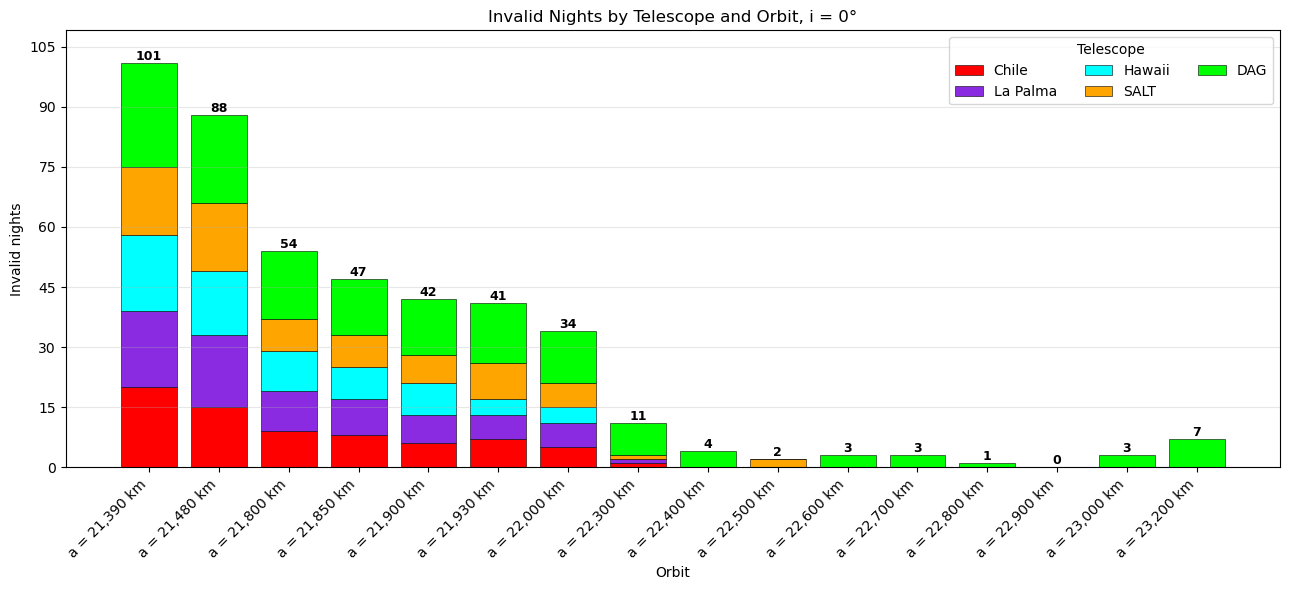

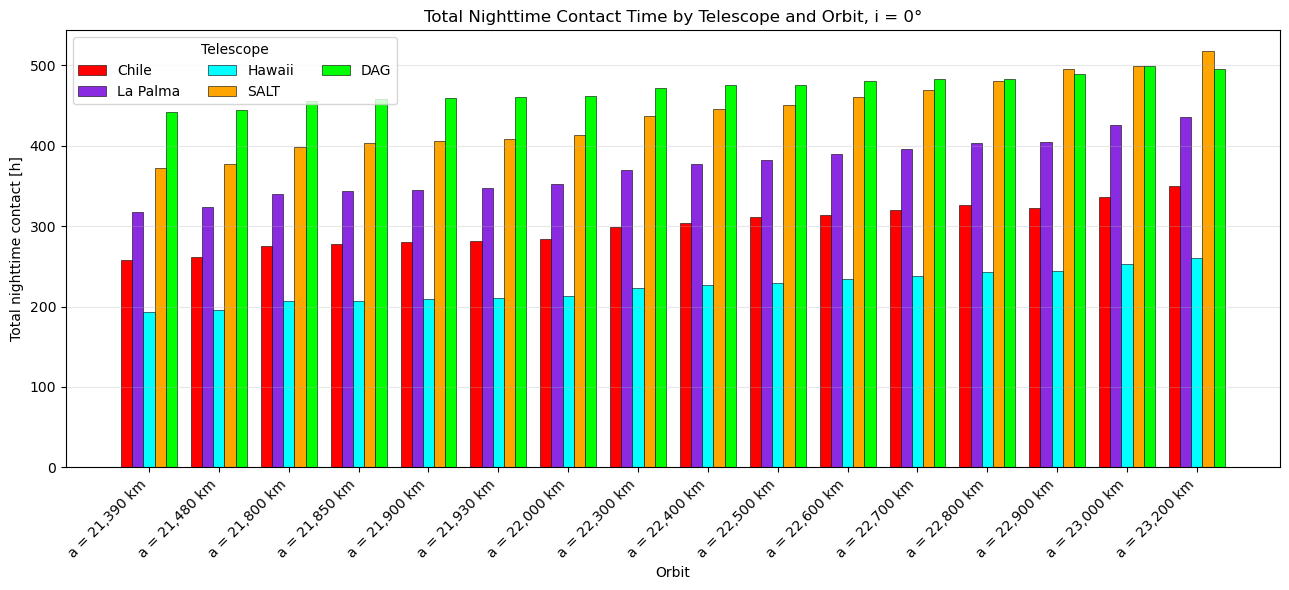

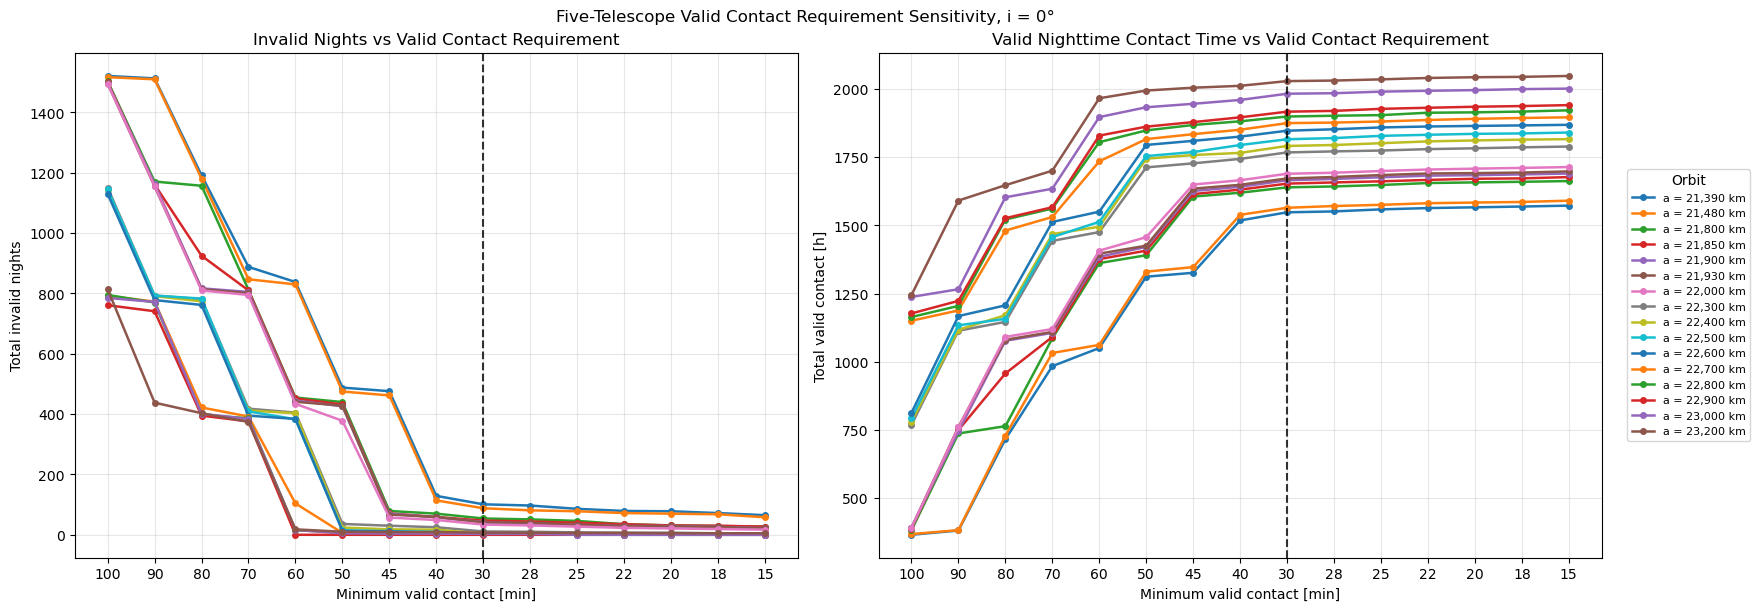

In [7]:
# Five-telescope visibility plots

orbit_order = [case["name"] for case in CASES]
orbit_labels = [orbit_label(case) for case in CASES]
x = np.arange(len(CASES))
bar_width = 0.8 / len(VISIBILITY_TELESCOPES)

# Five-telescope invalid nights

fig, ax = plt.subplots(figsize=(max(13, 0.8 * len(CASES)), 6))
invalid_night_totals = np.zeros(len(CASES))

for telescope in VISIBILITY_TELESCOPES:
    telescope_data = (
        visibility_invalid_nights[visibility_invalid_nights["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order))
    values = telescope_data["Invalid nights"].to_numpy()
    ax.bar(x, values, bottom=invalid_night_totals, color=VISIBILITY_COLORS[telescope], edgecolor="black", linewidth=0.4, label=telescope)
    invalid_night_totals += values

for position, total in zip(x, invalid_night_totals):
    ax.text(position, total, f"{int(total)}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title(plot_title("Invalid Nights by Telescope and Orbit"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Invalid nights")
ax.set_xticks(x)
ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
ax.margins(y=0.08)
fig.tight_layout()
save_figure(fig, "five_telescope_invalid_nights_by_orbit.png")
plt.show()

# Five-telescope total nighttime contact time

fig, ax = plt.subplots(figsize=(max(13, 0.8 * len(CASES)), 6))

for telescope_index, telescope in enumerate(VISIBILITY_TELESCOPES):
    telescope_data = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order))
    positions = x + (telescope_index - (len(VISIBILITY_TELESCOPES) - 1) / 2) * bar_width
    ax.bar(positions, telescope_data["Total nighttime contact [h]"], width=bar_width, color=VISIBILITY_COLORS[telescope], edgecolor="black", linewidth=0.4, label=telescope)

ax.set_title(plot_title("Total Nighttime Contact Time by Telescope and Orbit"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Total nighttime contact [h]")
ax.set_xticks(x)
ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
fig.tight_layout()
save_figure(fig, "five_telescope_total_nighttime_contact.png")
plt.show()

# Five-telescope valid nighttime contact requirement sensitivity

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
x_requirement = np.arange(len(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

for case in CASES:
    orbit_data = (
        visibility_sensitivity[visibility_sensitivity["Orbit"] == case["name"]]
        .set_index("Minimum valid contact [min]")
        .reindex(VISIBILITY_CONTACT_REQUIREMENTS_MIN))
    axes[0].plot(x_requirement, orbit_data["Total invalid nights"], marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))
    axes[1].plot(x_requirement, orbit_data["Total valid contact [h]"], marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))

axes[0].set_title("Invalid Nights vs Valid Contact Requirement")
axes[0].set_xlabel("Minimum valid contact [min]")
axes[0].set_ylabel("Total invalid nights")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

axes[1].set_title("Valid Nighttime Contact Time vs Valid Contact Requirement")
axes[1].set_xlabel("Minimum valid contact [min]")
axes[1].set_ylabel("Total valid contact [h]")

for ax in axes:
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(VISIBILITY_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(VISIBILITY_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN), color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Orbit", loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Five-Telescope Valid Contact Requirement Sensitivity"))
save_figure(fig, "five_telescope_valid_contact_requirement_sensitivity.png")
plt.show()

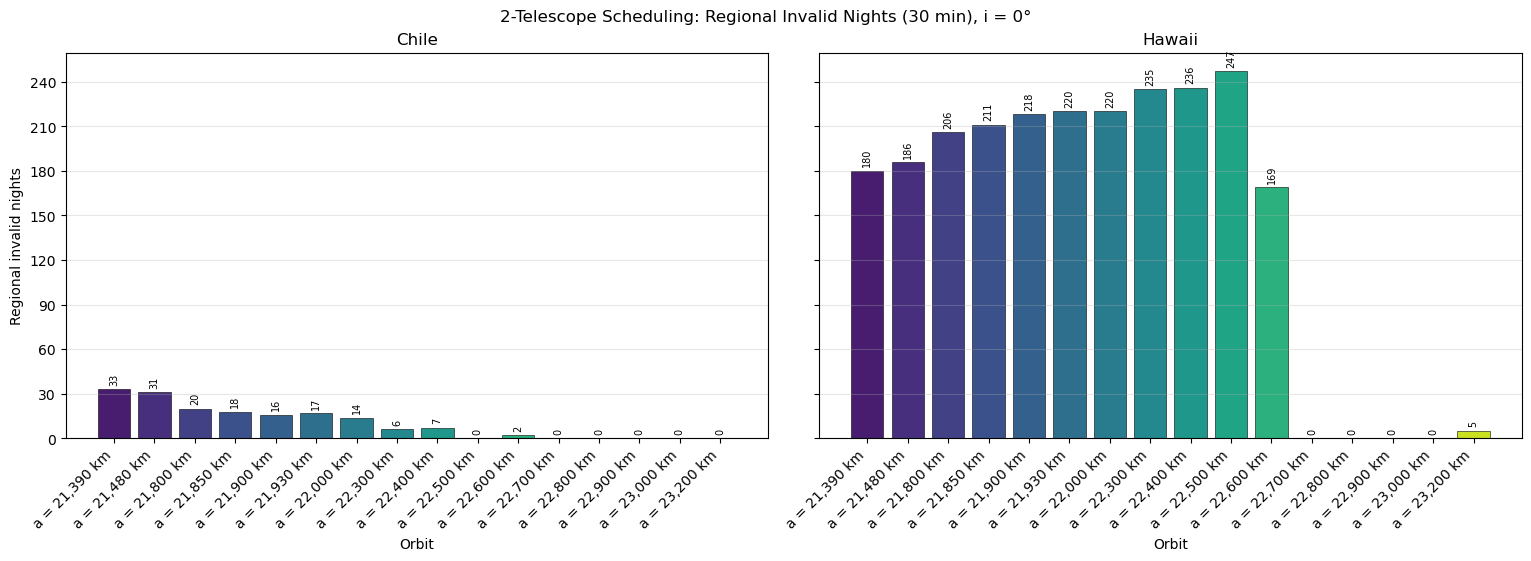

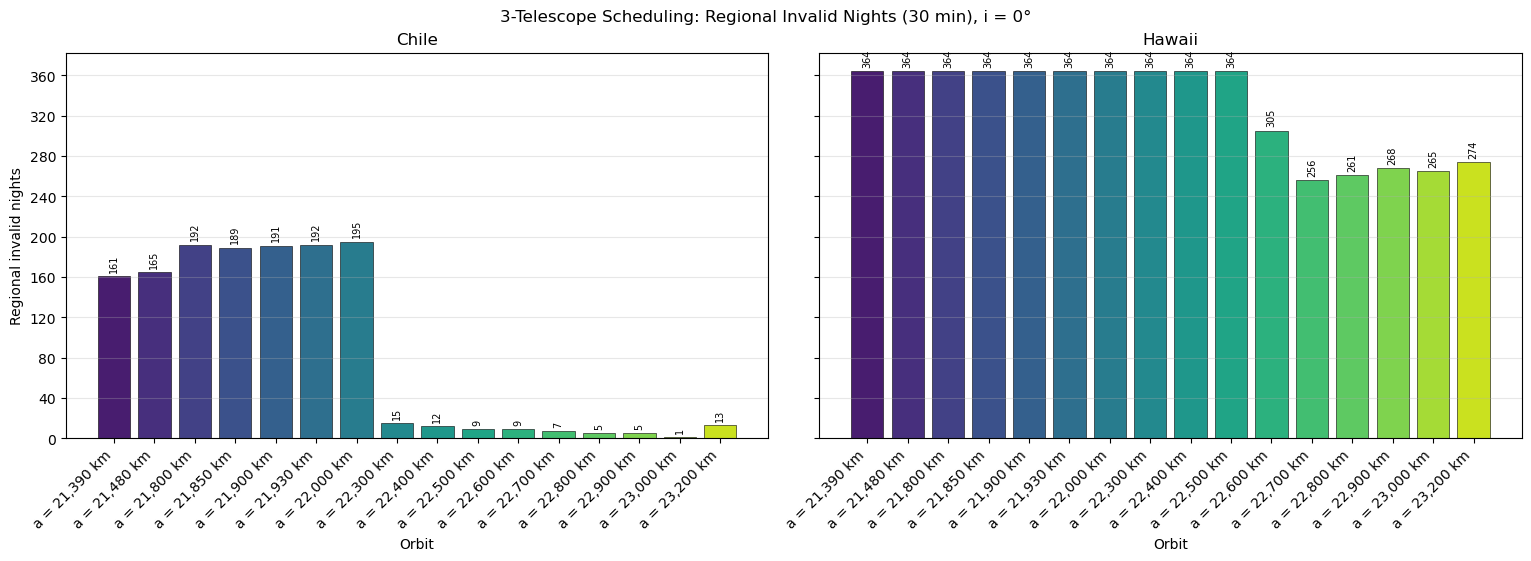

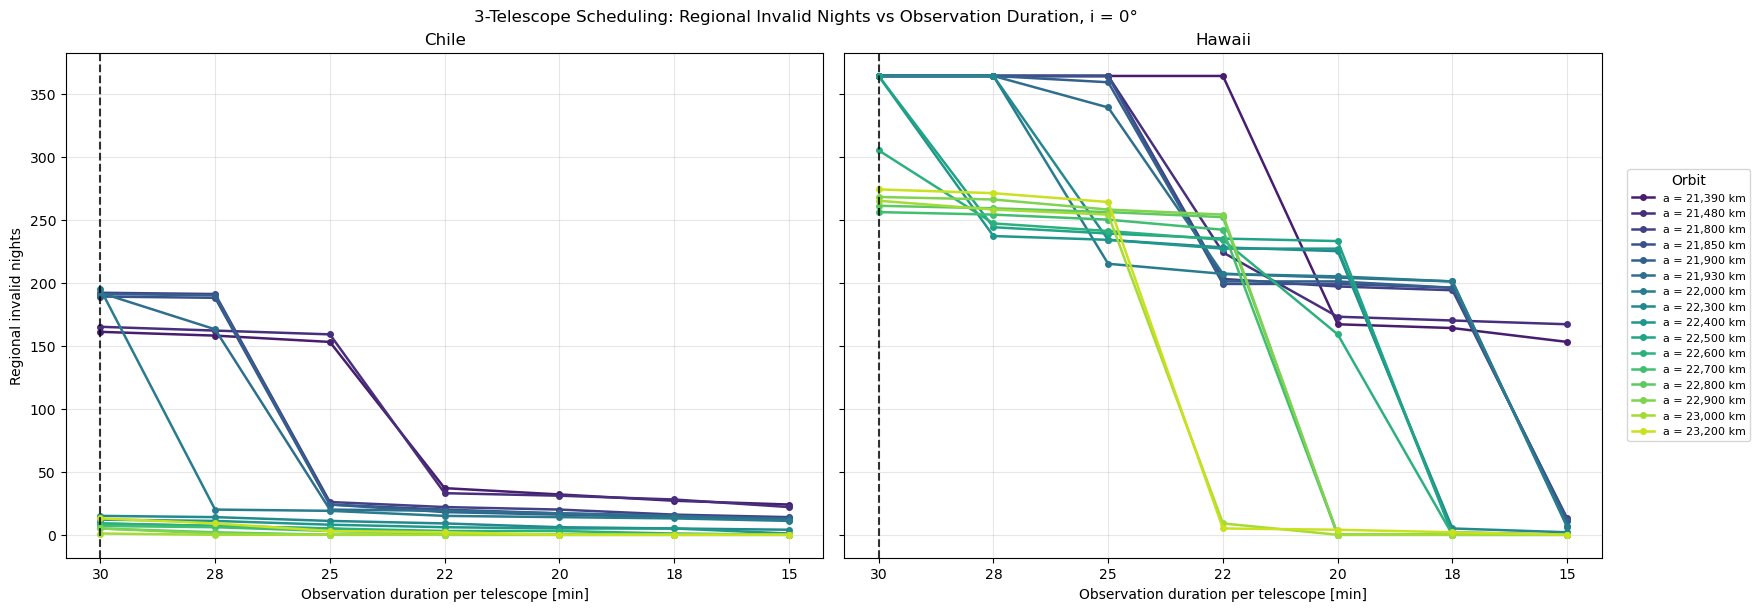

In [8]:
# Regional smart scheduling plots

current_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"] == CURRENT_CONTACT_REQUIREMENT_MIN]

def plot_regional_invalid_nights(value_column, title, filename):
    """Plot Chile and Hawaii invalid nights for all orbit cases."""
    fig, axes = plt.subplots(1, len(REGIONAL_TELESCOPES), figsize=(max(14, 0.95 * len(CASES)), 5.5), sharey=True, constrained_layout=True)

    if len(REGIONAL_TELESCOPES) == 1:
        axes = [axes]

    case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, len(CASES)))

    for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
        region_data = (
            current_scheduling[current_scheduling["Region"] == region_name]
            .set_index("Orbit").reindex(orbit_order))
        values = region_data[value_column].to_numpy()
        bars = ax.bar(x, values, color=case_colors, edgecolor="black", linewidth=0.4)
        ax.bar_label(bars, labels=[f"{int(value)}" for value in values], padding=3, fontsize=7, rotation=90)
        ax.set_title(region_name)
        ax.set_xlabel("Orbit")
        ax.set_xticks(x)
        ax.set_xticklabels(orbit_labels, rotation=45, ha="right")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel("Regional invalid nights")
    fig.suptitle(plot_title(title))
    save_figure(fig, filename)
    plt.show()

plot_regional_invalid_nights(
    "Two-telescope invalid nights",
    f"2-Telescope Scheduling: Regional Invalid Nights ({CURRENT_CONTACT_REQUIREMENT_MIN:g} min)",
    "two_telescope_invalid_nights_by_orbit.png")

plot_regional_invalid_nights(
    "Three-telescope invalid nights",
    f"3-Telescope Scheduling: Regional Invalid Nights ({CURRENT_CONTACT_REQUIREMENT_MIN:g} min)",
    "three_telescope_invalid_nights_by_orbit.png")

# 3-Telescope Scheduling observation-duration sensitivity

fig, axes = plt.subplots(1, len(REGIONAL_TELESCOPES), figsize=(16, 6), sharey=True, constrained_layout=True)

if len(REGIONAL_TELESCOPES) == 1:
    axes = [axes]

x_requirement = np.arange(len(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, len(CASES)))

for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
    region_data = scheduling_sensitivity[scheduling_sensitivity["Region"] == region_name]

    for case, color in zip(CASES, case_colors):
        orbit_data = (
            region_data[region_data["Orbit"] == case["name"]]
            .set_index("Minimum valid contact [min]")
            .reindex(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
        ax.plot(x_requirement, orbit_data["Three-telescope invalid nights"], marker="o", linewidth=1.8, markersize=4, color=color, label=orbit_label(case))

    ax.set_title(region_name)
    ax.set_xlabel("Observation duration per telescope [min]")
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(SCHEDULING_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(SCHEDULING_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN), color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Regional invalid nights")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Orbit", loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("3-Telescope Scheduling: Regional Invalid Nights vs Observation Duration"))
save_figure(fig, "three_telescope_valid_contact_requirement_sensitivity.png")
plt.show()

## Orbit ranking:

Each orbit is ranked separately for every criterion: higher nighttime contact time and fewer invalid nights receive better ranks. The unweighted score sums all criterion ranks equally, while the weighted score multiplies each rank by an editable importance weight before summing. The lowest total score ranks highest.

The four regional criteria use smart-scheduled regional invalid nights for Chile and Hawaii:

- **2-Telescope Scheduling** considers only the fixed pair selected for each region in TWO_TELESCOPE_SELECTION. The third telescope is excluded from the nighttime windows, scheduling decisions, cadence constraints and summary counts. A regional night is invalid if either selected telescope exceeds its consecutive missed-night allowance.
- **3-Telescope Scheduling** considers all three regional telescopes. A regional night is invalid if any of the three exceeds its consecutive missed-night allowance.

Each regional invalid night is counted once, regardless of how many included telescopes violate cadence. With MAX_CONSECUTIVE_MISSED_NIGHTS = 1, the first consecutive missed night is allowed; the second and subsequent consecutive missed nights are invalid. A telescope may miss an observation without making that night invalid.

The observation durations are controlled by CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN and CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN in the ranking cell. Use the same duration for a direct comparison. For the same analysed nights and observation duration, the optimised two-telescope case cannot have more regional invalid nights than the three-telescope case.

All contact-time ranking criteria use nighttime contact: total nighttime contact or valid nighttime contact, as labelled.

**Caveat**: This is a relative rank-based comparison. It considers orbit ordering rather than the size of the differences. The selected weights are subjective and should be tested for sensitivity.

### Unweighted orbit ranking:

Each orbit is ranked across 11 equally weighted performance criteria. Nighttime contact-time metrics are ranked in descending order, while invalid-night metrics are ranked in ascending order.

Ranks are assigned using `method="min"`, so tied orbits receive the same best applicable rank. The total ranking score is the sum of all individual criterion ranks, and the lowest total score determines overall rank 1. Tied values receive the same rank.

In [9]:
# Orbit ranking
# Every listed criterion has equal weight. Lower criterion and total scores are better.

# Change this if needed!!
# Observation durations used in the smart-scheduled regional ranking
CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN = 30
CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN = 22

if CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

if CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN not in SCHEDULING_CONTACT_REQUIREMENTS_MIN:
    raise ValueError("CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN must be included in SCHEDULING_CONTACT_REQUIREMENTS_MIN.")

ranking_values = pd.DataFrame(index=orbit_order)

for telescope in VISIBILITY_TELESCOPES:
    values = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(orbit_order)["Total nighttime contact [h]"])
    ranking_values[f"{telescope} total nighttime contact [h]"] = values

current_visibility = (
    visibility_sensitivity[visibility_sensitivity["Minimum valid contact [min]"] == CURRENT_CONTACT_REQUIREMENT_MIN]
    .set_index("Orbit").reindex(orbit_order))

ranking_values["5-telescope invalid nights"] = visibility_invalid_nights.groupby("Orbit")["Invalid nights"].sum().reindex(orbit_order)
ranking_values["5-telescope valid nighttime contact [h]"] = current_visibility["Total valid contact [h]"]

current_two_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"] == CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN]

current_three_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"] == CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN]

for region_name in REGIONAL_TELESCOPES:
    two_telescope_data = (
        current_two_telescope_scheduling[current_two_telescope_scheduling["Region"] == region_name]
        .set_index("Orbit").reindex(orbit_order))
    three_telescope_data = (
        current_three_telescope_scheduling[current_three_telescope_scheduling["Region"] == region_name]
        .set_index("Orbit").reindex(orbit_order))

    ranking_values[f"{region_name} 2-Telescope Scheduling regional invalid nights"] = two_telescope_data["Two-telescope invalid nights"]
    ranking_values[f"{region_name} 3-Telescope Scheduling regional invalid nights"] = three_telescope_data["Three-telescope invalid nights"]

higher_is_better = {
    **{f"{telescope} total nighttime contact [h]": True for telescope in VISIBILITY_TELESCOPES},
    "5-telescope invalid nights": False,
    "5-telescope valid nighttime contact [h]": True,
    "Chile 2-Telescope Scheduling regional invalid nights": False,
    "Chile 3-Telescope Scheduling regional invalid nights": False,
    "Hawaii 2-Telescope Scheduling regional invalid nights": False,
    "Hawaii 3-Telescope Scheduling regional invalid nights": False}

criterion_ranks = pd.DataFrame(index=orbit_order)

for criterion, maximise in higher_is_better.items():
    criterion_ranks[f"{criterion} rank"] = ranking_values[criterion].rank(method="min", ascending=not maximise)

criterion_ranks["Total ranking score"] = criterion_ranks.sum(axis=1)
criterion_ranks["Overall rank"] = criterion_ranks["Total ranking score"].rank(method="min", ascending=True).astype(int)
criterion_ranks.index.name = "Orbit"

overall_ranking = criterion_ranks.sort_values(["Overall rank", "Total ranking score"])
winner_rows = []

for criterion, maximise in higher_is_better.items():
    best_value = ranking_values[criterion].max() if maximise else ranking_values[criterion].min()
    winners = ranking_values.index[np.isclose(ranking_values[criterion], best_value, rtol=0, atol=1e-9)]
    winner_rows.append({"Criterion": criterion, "Best orbit": " / ".join(winners),
        "Best value": best_value, "Preferred direction": "Higher" if maximise else "Lower"})

criterion_winners = pd.DataFrame(winner_rows)

print("Best orbit for each criterion:")
display(criterion_winners.round(2).style.hide(axis="index"))

print("\nOverall ranking:")
display(overall_ranking.round(2))

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    ranking_values.to_csv(output / "ranking_criterion_values.csv")
    criterion_ranks.to_csv(output / "ranking_criterion_ranks.csv")
    criterion_winners.to_csv(output / "ranking_criterion_winners.csv", index=False)
    overall_ranking.to_csv(output / "overall_orbit_ranking.csv")

Best orbit for each criterion:


Criterion,Best orbit,Best value,Preferred direction
Chile total nighttime contact [h],"a = 23,200 km, i = 0°",349.620000,Higher
La Palma total nighttime contact [h],"a = 23,200 km, i = 0°",435.300000,Higher
Hawaii total nighttime contact [h],"a = 23,200 km, i = 0°",260.860000,Higher
SALT total nighttime contact [h],"a = 23,200 km, i = 0°",517.640000,Higher
DAG total nighttime contact [h],"a = 23,000 km, i = 0°",499.170000,Higher
5-telescope invalid nights,"a = 22,900 km, i = 0°",0.000000,Lower
5-telescope valid nighttime contact [h],"a = 23,200 km, i = 0°",2029.320000,Higher
Chile 2-Telescope Scheduling regional invalid nights,"a = 22,500 km, i = 0° / a = 22,700 km, i = 0° / a = 22,800 km, i = 0° / a = 22,900 km, i = 0° / a = 23,000 km, i = 0° / a = 23,200 km, i = 0°",0.000000,Lower
Chile 3-Telescope Scheduling regional invalid nights,"a = 22,500 km, i = 0° / a = 22,800 km, i = 0° / a = 22,900 km, i = 0° / a = 23,000 km, i = 0°",0.000000,Lower
Hawaii 2-Telescope Scheduling regional invalid nights,"a = 22,700 km, i = 0° / a = 22,800 km, i = 0° / a = 22,900 km, i = 0° / a = 23,000 km, i = 0°",0.000000,Lower



Overall ranking:


,Chile total nighttime contact [h] rank,La Palma total nighttime contact [h] rank,Hawaii total nighttime contact [h] rank,SALT total nighttime contact [h] rank,DAG total nighttime contact [h] rank,5-telescope invalid nights rank,5-telescope valid nighttime contact [h] rank,Chile 2-Telescope Scheduling regional invalid nights rank,Chile 3-Telescope Scheduling regional invalid nights rank,Hawaii 2-Telescope Scheduling regional invalid nights rank,Hawaii 3-Telescope Scheduling regional invalid nights rank,Total ranking score,Overall rank
Orbit,,,,,,,,,,,,,
"a = 23,000 km, i = 0°",2.0,2.0,2.0,2.0,1.0,4.0,2.0,1.0,1.0,1.0,2.0,20.0,1
"a = 23,200 km, i = 0°",1.0,1.0,1.0,1.0,2.0,8.0,1.0,1.0,6.0,5.0,1.0,28.0,2
"a = 22,900 km, i = 0°",4.0,3.0,3.0,3.0,3.0,1.0,3.0,1.0,1.0,1.0,15.0,38.0,3
"a = 22,800 km, i = 0°",3.0,4.0,4.0,4.0,4.0,2.0,4.0,1.0,1.0,1.0,14.0,42.0,4
"a = 22,700 km, i = 0°",5.0,5.0,5.0,5.0,5.0,4.0,5.0,1.0,5.0,1.0,13.0,54.0,5
"a = 22,600 km, i = 0°",6.0,6.0,6.0,6.0,6.0,4.0,6.0,7.0,7.0,6.0,11.0,71.0,6
"a = 22,500 km, i = 0°",7.0,7.0,7.0,7.0,7.0,3.0,7.0,1.0,1.0,16.0,12.0,75.0,7
"a = 22,400 km, i = 0°",8.0,8.0,8.0,8.0,8.0,7.0,8.0,9.0,8.0,15.0,9.0,96.0,8
"a = 22,300 km, i = 0°",9.0,9.0,9.0,9.0,9.0,9.0,9.0,8.0,9.0,14.0,10.0,104.0,9


### Weighted orbit ranking:

Each performance criterion is ranked in the same direction as in the unweighted ranking. The resulting rank is multiplied by its assigned weight, and the weighted ranks are summed. The orbit with the lowest total weighted score receives overall weighted rank 1.

Nighttime contact-time criteria initially have low and equal weights. Five-telescope invalid nights have the highest weight, followed by 2-Telescope Scheduling and then 3-Telescope Scheduling invalid nights. Telescope and regional multipliers can be adjusted independently.

In [10]:
# Weighted orbit ranking
# Criterion ranks are multiplied by editable weights. Lower weighted and total scores are better.

# Settings to change !!
CONTACT_TIME_WEIGHT = 1.0
TELESCOPE_WEIGHTS = {telescope: 1.0 for telescope in VISIBILITY_TELESCOPES}
# eg. to make Hawaii twice as important as others, set TELESCOPE_WEIGHTS = {"Chile": 1.0, "La Palma": 1.0, "Hawaii": 2.0, "SALT": 1.0, "DAG": 1.0}
FIVE_TELESCOPE_VALID_CONTACT_WEIGHT = 1.0
FIVE_TELESCOPE_INVALID_NIGHTS_WEIGHT = 5.0
TWO_TELESCOPE_INVALID_NIGHTS_WEIGHT = 4.0
THREE_TELESCOPE_INVALID_NIGHTS_WEIGHT = 3.0
REGION_WEIGHTS = {region_name: 1.0 for region_name in REGIONAL_TELESCOPES}

criterion_weights = {
    **{f"{telescope} total nighttime contact [h]": CONTACT_TIME_WEIGHT * TELESCOPE_WEIGHTS[telescope] for telescope in VISIBILITY_TELESCOPES},
    "5-telescope invalid nights": FIVE_TELESCOPE_INVALID_NIGHTS_WEIGHT,
    "5-telescope valid nighttime contact [h]": FIVE_TELESCOPE_VALID_CONTACT_WEIGHT,
    **{f"{region_name} 2-Telescope Scheduling regional invalid nights": TWO_TELESCOPE_INVALID_NIGHTS_WEIGHT * REGION_WEIGHTS[region_name] for region_name in REGIONAL_TELESCOPES},
    **{f"{region_name} 3-Telescope Scheduling regional invalid nights": THREE_TELESCOPE_INVALID_NIGHTS_WEIGHT * REGION_WEIGHTS[region_name] for region_name in REGIONAL_TELESCOPES}}

if set(criterion_weights) != set(higher_is_better):
    raise ValueError("criterion_weights must contain exactly the same criteria as higher_is_better.")

weighted_criterion_ranks = pd.DataFrame(index=orbit_order)

for criterion, maximise in higher_is_better.items():
    criterion_rank = ranking_values[criterion].rank(method="min", ascending=not maximise)
    weighted_criterion_ranks[f"{criterion} weighted rank"] = criterion_rank * criterion_weights[criterion]

weighted_criterion_ranks["Total weighted score"] = weighted_criterion_ranks.sum(axis=1)
weighted_criterion_ranks["Overall weighted rank"] = weighted_criterion_ranks["Total weighted score"].rank(method="min", ascending=True).astype(int)
weighted_criterion_ranks.index.name = "Orbit"

weighted_overall_ranking = weighted_criterion_ranks.sort_values(["Overall weighted rank", "Total weighted score"])

weight_table = pd.DataFrame({
    "Criterion": list(higher_is_better),
    "Weight": [criterion_weights[criterion] for criterion in higher_is_better]})

print("Weighted ranking criteria:")
display(weight_table.round(2).style.hide(axis="index"))

print("\nWeighted overall ranking:")
display(weighted_overall_ranking.round(2))

if SAVE_TABLES:
    output = BASE / "analysis_tables"
    output.mkdir(parents=True, exist_ok=True)
    weight_table.to_csv(output / "weighted_ranking_criterion_weights.csv", index=False)
    weighted_criterion_ranks.to_csv(output / "weighted_ranking_criterion_scores.csv")
    weighted_overall_ranking.to_csv(output / "weighted_overall_orbit_ranking.csv")

Weighted ranking criteria:


Criterion,Weight
Chile total nighttime contact [h],1.000000
La Palma total nighttime contact [h],1.000000
Hawaii total nighttime contact [h],1.000000
SALT total nighttime contact [h],1.000000
DAG total nighttime contact [h],1.000000
5-telescope invalid nights,5.000000
5-telescope valid nighttime contact [h],1.000000
Chile 2-Telescope Scheduling regional invalid nights,4.000000
Chile 3-Telescope Scheduling regional invalid nights,3.000000
Hawaii 2-Telescope Scheduling regional invalid nights,4.000000



Weighted overall ranking:


,Chile total nighttime contact [h] weighted rank,La Palma total nighttime contact [h] weighted rank,Hawaii total nighttime contact [h] weighted rank,SALT total nighttime contact [h] weighted rank,DAG total nighttime contact [h] weighted rank,5-telescope invalid nights weighted rank,5-telescope valid nighttime contact [h] weighted rank,Chile 2-Telescope Scheduling regional invalid nights weighted rank,Chile 3-Telescope Scheduling regional invalid nights weighted rank,Hawaii 2-Telescope Scheduling regional invalid nights weighted rank,Hawaii 3-Telescope Scheduling regional invalid nights weighted rank,Total weighted score,Overall weighted rank
Orbit,,,,,,,,,,,,,
"a = 23,000 km, i = 0°",2.0,2.0,2.0,2.0,1.0,20.0,2.0,4.0,3.0,4.0,6.0,48.0,1
"a = 22,900 km, i = 0°",4.0,3.0,3.0,3.0,3.0,5.0,3.0,4.0,3.0,4.0,45.0,80.0,2
"a = 22,800 km, i = 0°",3.0,4.0,4.0,4.0,4.0,10.0,4.0,4.0,3.0,4.0,42.0,86.0,3
"a = 23,200 km, i = 0°",1.0,1.0,1.0,1.0,2.0,40.0,1.0,4.0,18.0,20.0,3.0,92.0,4
"a = 22,700 km, i = 0°",5.0,5.0,5.0,5.0,5.0,20.0,5.0,4.0,15.0,4.0,39.0,112.0,5
"a = 22,600 km, i = 0°",6.0,6.0,6.0,6.0,6.0,20.0,6.0,28.0,21.0,24.0,33.0,162.0,6
"a = 22,500 km, i = 0°",7.0,7.0,7.0,7.0,7.0,15.0,7.0,4.0,3.0,64.0,36.0,164.0,7
"a = 22,400 km, i = 0°",8.0,8.0,8.0,8.0,8.0,35.0,8.0,36.0,24.0,60.0,27.0,230.0,8
"a = 22,300 km, i = 0°",9.0,9.0,9.0,9.0,9.0,45.0,9.0,32.0,27.0,56.0,30.0,244.0,9


Top four weighted-ranked orbits:


,Total weighted score,Overall weighted rank
Orbit,,
"a = 23,000 km, i = 0°",48.0,1
"a = 22,900 km, i = 0°",80.0,2
"a = 22,800 km, i = 0°",86.0,3
"a = 23,200 km, i = 0°",92.0,4


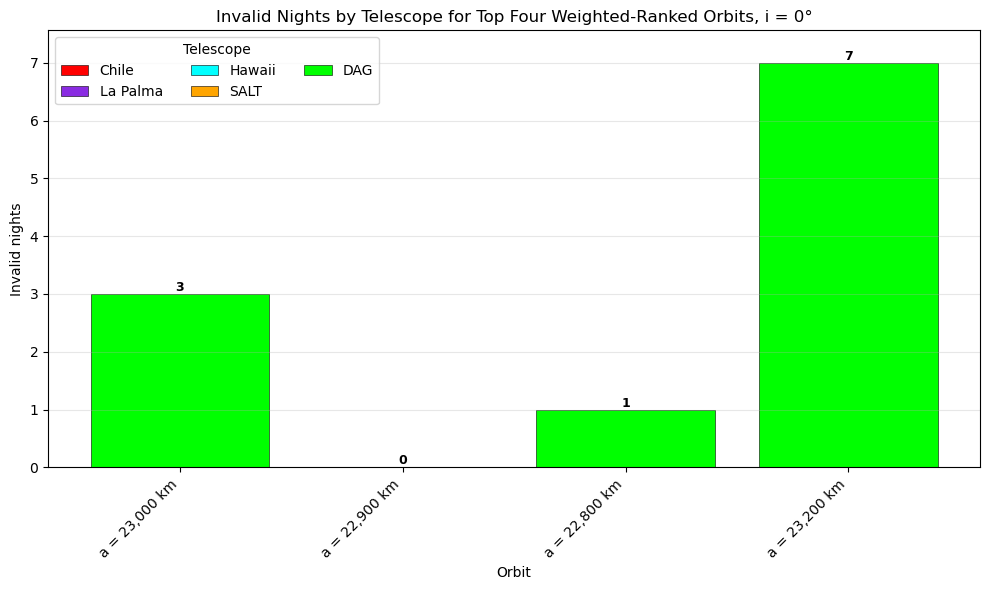

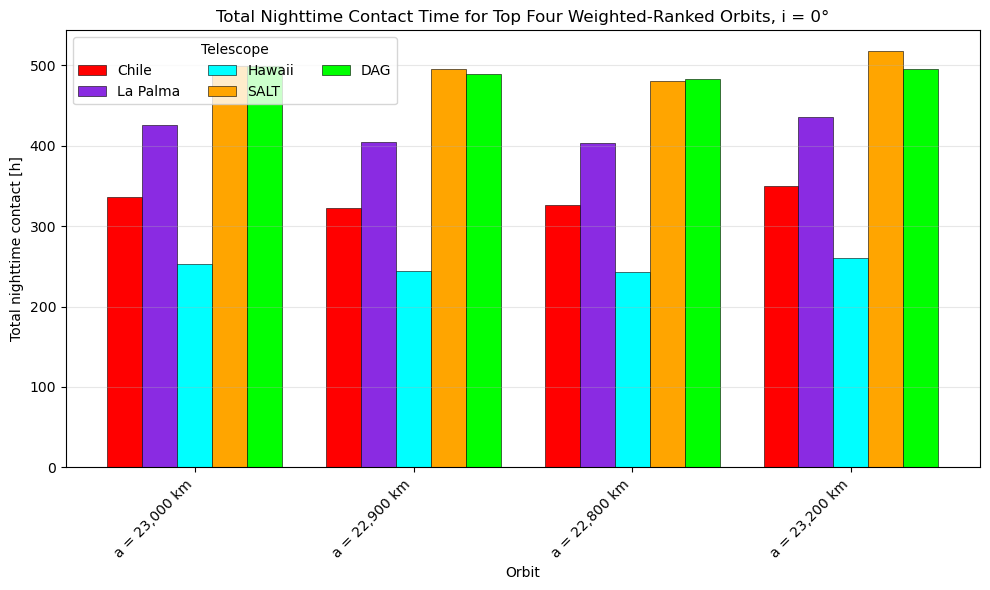

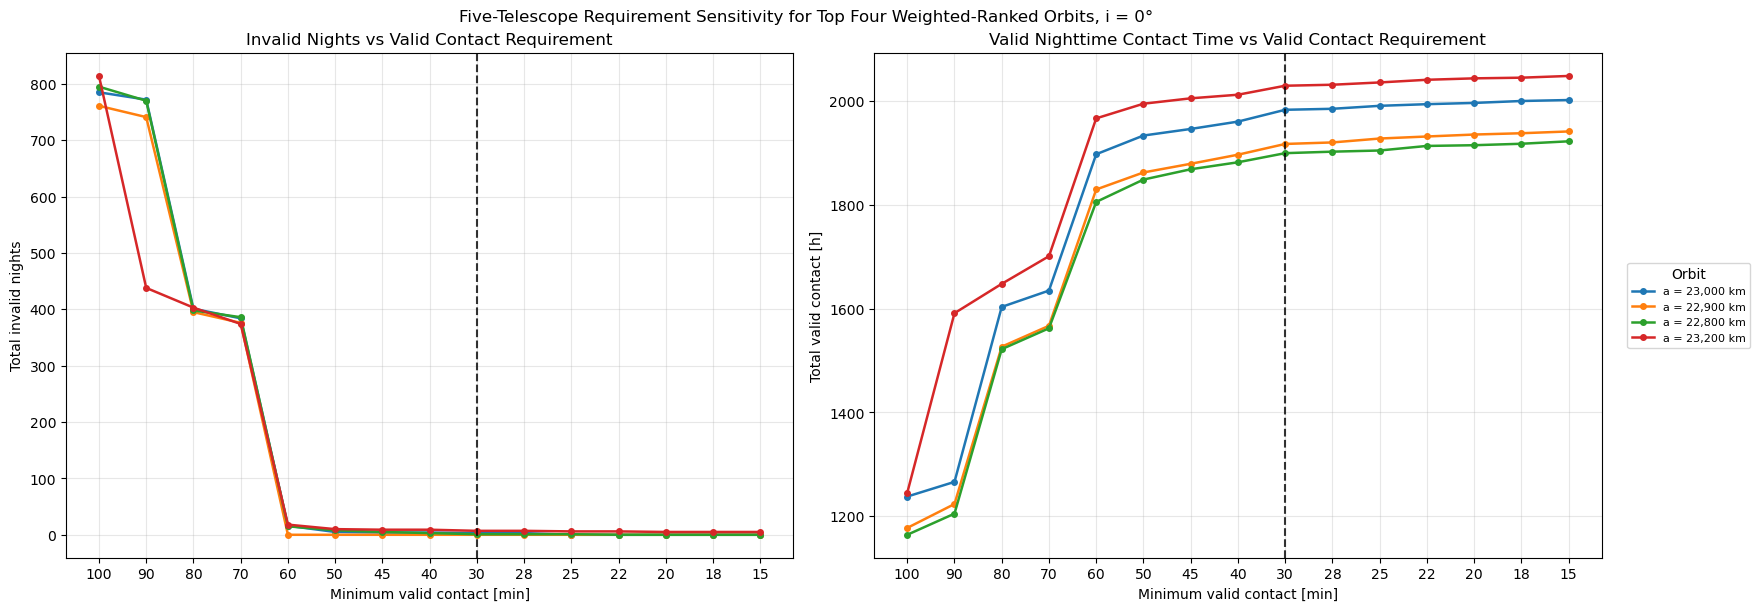

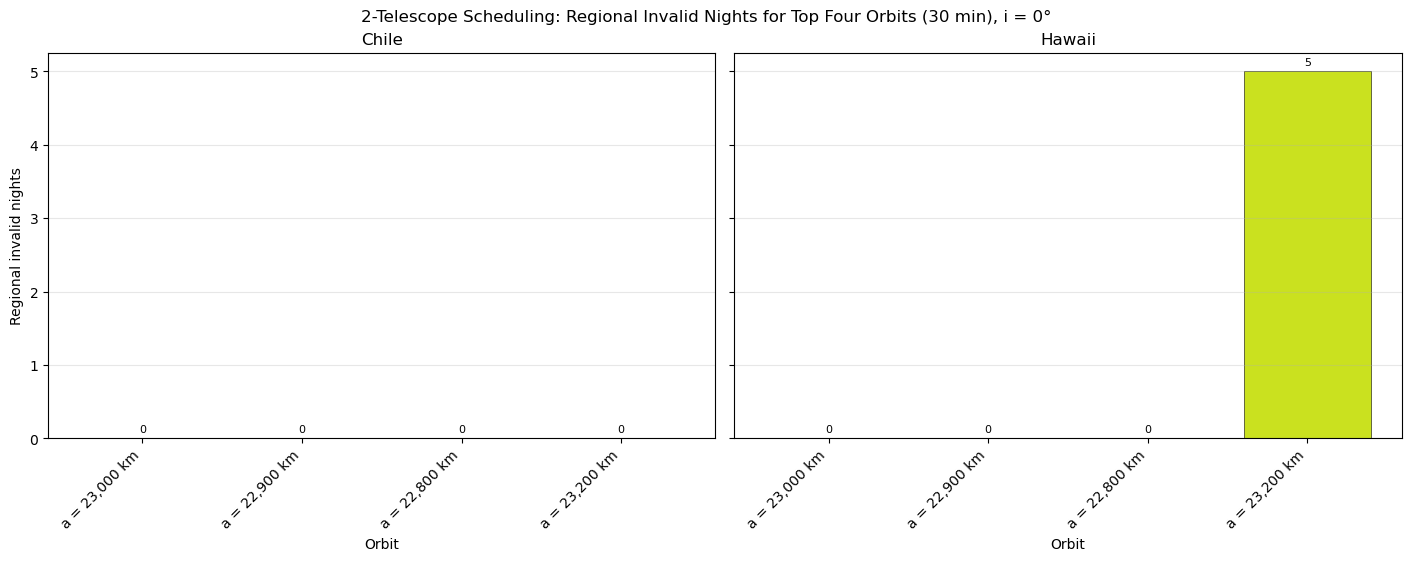

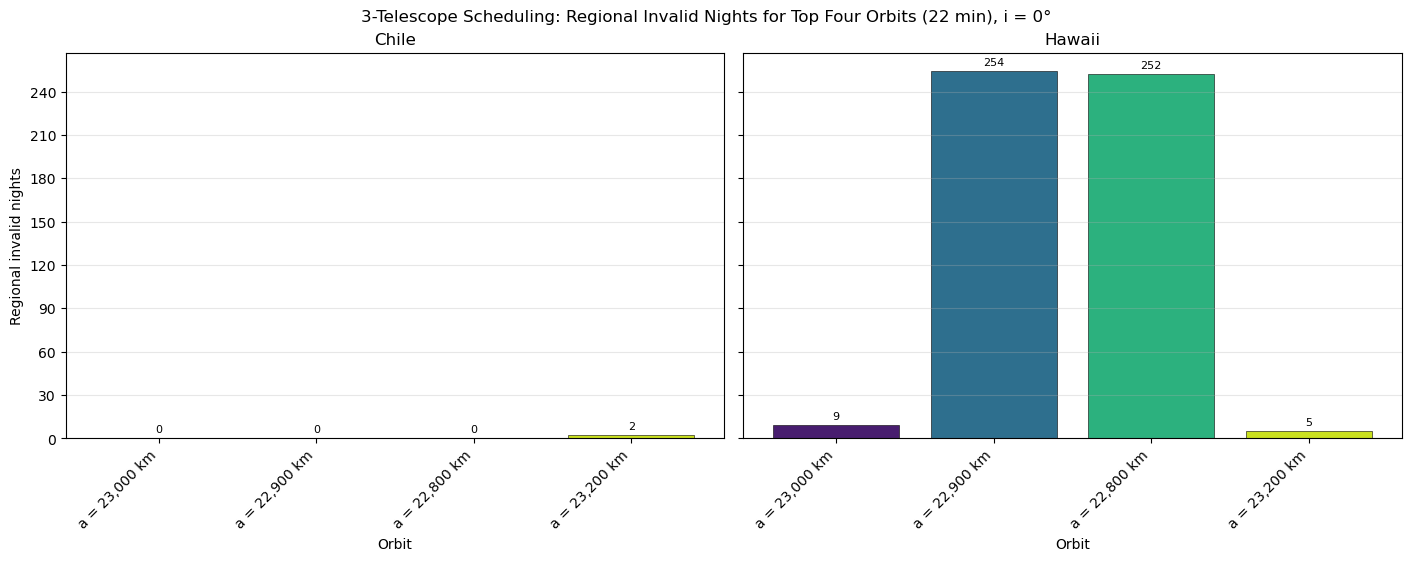

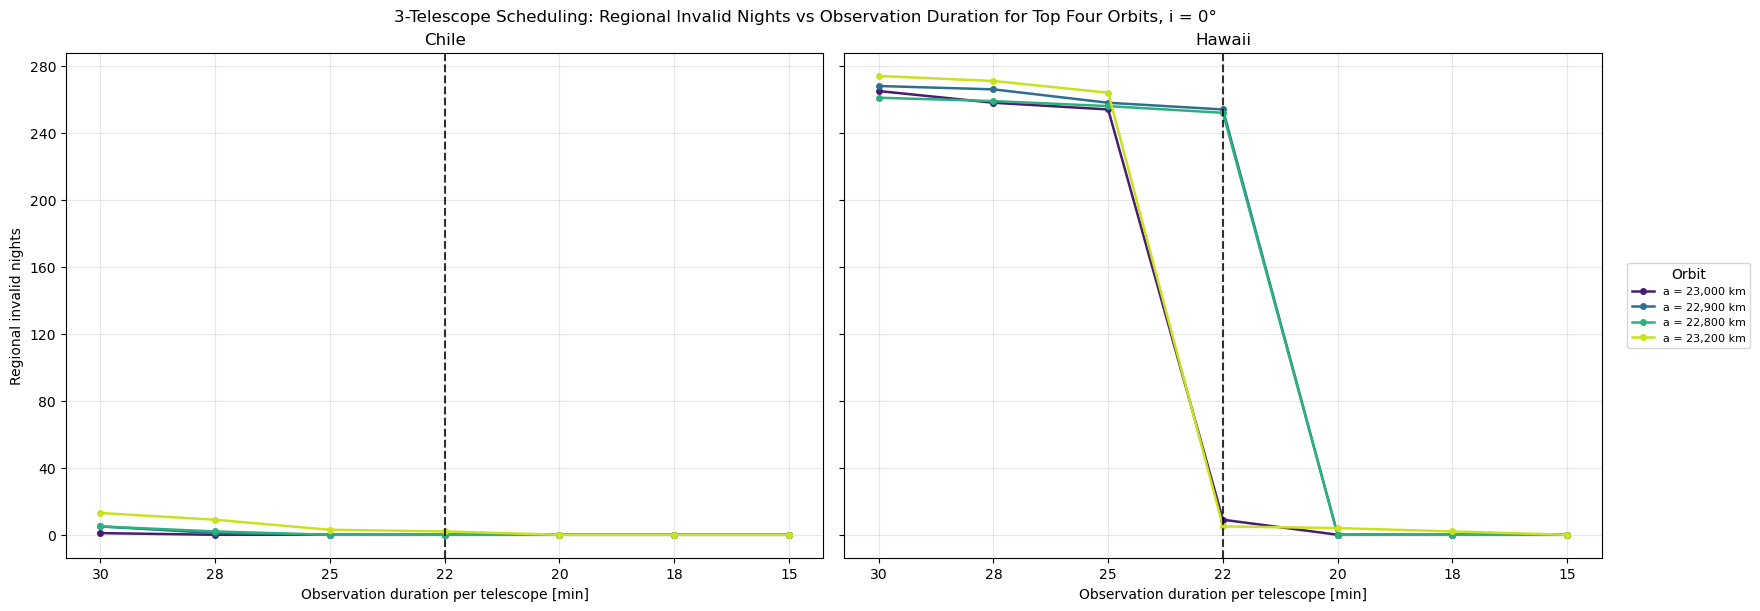

In [11]:
# Repeat all plots for the top four weighted-ranked orbits

# Number of top orbits to display in plots:
TOP_ORBIT_COUNT = 4

if len(weighted_overall_ranking) < TOP_ORBIT_COUNT:
    raise ValueError(f"At least {TOP_ORBIT_COUNT} orbits are required.")

top_orbit_order = weighted_overall_ranking.index[:TOP_ORBIT_COUNT].tolist()
top_cases = [next(case for case in CASES if case["name"] == orbit) for orbit in top_orbit_order]
top_orbit_labels = [orbit_label(case) for case in top_cases]
top_x = np.arange(TOP_ORBIT_COUNT)

print("Top four weighted-ranked orbits:")
display(weighted_overall_ranking.loc[top_orbit_order, ["Total weighted score", "Overall weighted rank"]].round(2))

# Five-telescope invalid nights

fig, ax = plt.subplots(figsize=(10, 6))
top_invalid_night_totals = np.zeros(TOP_ORBIT_COUNT)

for telescope in VISIBILITY_TELESCOPES:
    telescope_data = (
        visibility_invalid_nights[visibility_invalid_nights["Telescope"] == telescope]
        .set_index("Orbit").reindex(top_orbit_order))
    values = telescope_data["Invalid nights"].to_numpy()
    ax.bar(top_x, values, bottom=top_invalid_night_totals, color=VISIBILITY_COLORS[telescope], edgecolor="black", linewidth=0.4, label=telescope)
    top_invalid_night_totals += values

for position, total in zip(top_x, top_invalid_night_totals):
    ax.text(position, total, f"{int(total)}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_title(plot_title("Invalid Nights by Telescope for Top Four Weighted-Ranked Orbits"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Invalid nights")
ax.set_xticks(top_x)
ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
ax.margins(y=0.08)
fig.tight_layout()
save_figure(fig, "top_four_five_telescope_invalid_nights_by_orbit.png")
plt.show()

# Five-telescope total nighttime contact time

bar_width = 0.8 / len(VISIBILITY_TELESCOPES)
fig, ax = plt.subplots(figsize=(10, 6))

for telescope_index, telescope in enumerate(VISIBILITY_TELESCOPES):
    telescope_data = (
        visibility_contact[visibility_contact["Telescope"] == telescope]
        .set_index("Orbit").reindex(top_orbit_order))
    positions = top_x + (telescope_index - (len(VISIBILITY_TELESCOPES) - 1) / 2) * bar_width
    ax.bar(positions, telescope_data["Total nighttime contact [h]"], width=bar_width, color=VISIBILITY_COLORS[telescope], edgecolor="black", linewidth=0.4, label=telescope)

ax.set_title(plot_title("Total Nighttime Contact Time for Top Four Weighted-Ranked Orbits"))
ax.set_xlabel("Orbit")
ax.set_ylabel("Total nighttime contact [h]")
ax.set_xticks(top_x)
ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Telescope", ncol=3)
fig.tight_layout()
save_figure(fig, "top_four_five_telescope_total_nighttime_contact.png")
plt.show()

# Five-telescope valid nighttime contact requirement sensitivity

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
x_requirement = np.arange(len(VISIBILITY_CONTACT_REQUIREMENTS_MIN))

for case in top_cases:
    orbit_data = (
        visibility_sensitivity[visibility_sensitivity["Orbit"] == case["name"]]
        .set_index("Minimum valid contact [min]")
        .reindex(VISIBILITY_CONTACT_REQUIREMENTS_MIN))
    axes[0].plot(x_requirement, orbit_data["Total invalid nights"], marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))
    axes[1].plot(x_requirement, orbit_data["Total valid contact [h]"], marker="o", linewidth=1.8, markersize=4, label=orbit_label(case))

axes[0].set_title("Invalid Nights vs Valid Contact Requirement")
axes[0].set_xlabel("Minimum valid contact [min]")
axes[0].set_ylabel("Total invalid nights")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

axes[1].set_title("Valid Nighttime Contact Time vs Valid Contact Requirement")
axes[1].set_xlabel("Minimum valid contact [min]")
axes[1].set_ylabel("Total valid contact [h]")

for ax in axes:
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(VISIBILITY_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(VISIBILITY_CONTACT_REQUIREMENTS_MIN.index(CURRENT_CONTACT_REQUIREMENT_MIN), color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Orbit", loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("Five-Telescope Requirement Sensitivity for Top Four Weighted-Ranked Orbits"))
save_figure(fig, "top_four_five_telescope_valid_contact_requirement_sensitivity.png")
plt.show()

# Regional 2-Telescope Scheduling and 3-Telescope Scheduling invalid nights

top_two_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"] == CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN]

top_three_telescope_scheduling = scheduling_sensitivity[
    scheduling_sensitivity["Minimum valid contact [min]"] == CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN]

def plot_top_regional_invalid_nights(scheduling_data, value_column, title, filename):
    """Plot Chile and Hawaii invalid nights for the top four orbits."""
    fig, axes = plt.subplots(1, len(REGIONAL_TELESCOPES), figsize=(14, 5.5), sharey=True, constrained_layout=True)

    if len(REGIONAL_TELESCOPES) == 1:
        axes = [axes]

    case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, TOP_ORBIT_COUNT))

    for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
        region_data = (
            scheduling_data[scheduling_data["Region"] == region_name]
            .set_index("Orbit").reindex(top_orbit_order))
        values = region_data[value_column].to_numpy()
        bars = ax.bar(top_x, values, color=case_colors, edgecolor="black", linewidth=0.4)
        ax.bar_label(bars, labels=[f"{int(value)}" for value in values], padding=3, fontsize=8)
        ax.set_title(region_name)
        ax.set_xlabel("Orbit")
        ax.set_xticks(top_x)
        ax.set_xticklabels(top_orbit_labels, rotation=45, ha="right")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel("Regional invalid nights")
    fig.suptitle(plot_title(title))
    save_figure(fig, filename)
    plt.show()

plot_top_regional_invalid_nights(
    top_two_telescope_scheduling,
    "Two-telescope invalid nights",
    f"2-Telescope Scheduling: Regional Invalid Nights for Top Four Orbits ({CURRENT_TWO_TELESCOPE_REQUIREMENT_MIN} min)",
    "top_four_two_telescope_invalid_nights_by_orbit.png")

plot_top_regional_invalid_nights(
    top_three_telescope_scheduling,
    "Three-telescope invalid nights",
    f"3-Telescope Scheduling: Regional Invalid Nights for Top Four Orbits ({CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN} min)",
    "top_four_three_telescope_invalid_nights_by_orbit.png")

# 3-Telescope Scheduling observation-duration sensitivity

fig, axes = plt.subplots(1, len(REGIONAL_TELESCOPES), figsize=(16, 6), sharey=True, constrained_layout=True)

if len(REGIONAL_TELESCOPES) == 1:
    axes = [axes]

x_requirement = np.arange(len(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
case_colors = plt.cm.viridis(np.linspace(0.08, 0.92, TOP_ORBIT_COUNT))

for ax, region_name in zip(axes, REGIONAL_TELESCOPES):
    region_data = scheduling_sensitivity[scheduling_sensitivity["Region"] == region_name]

    for case, color in zip(top_cases, case_colors):
        orbit_data = (
            region_data[region_data["Orbit"] == case["name"]]
            .set_index("Minimum valid contact [min]")
            .reindex(SCHEDULING_CONTACT_REQUIREMENTS_MIN))
        ax.plot(x_requirement, orbit_data["Three-telescope invalid nights"], marker="o", linewidth=1.8, markersize=4, color=color, label=orbit_label(case))

    ax.set_title(region_name)
    ax.set_xlabel("Observation duration per telescope [min]")
    ax.set_xticks(x_requirement)
    ax.set_xticklabels(SCHEDULING_CONTACT_REQUIREMENTS_MIN)
    ax.axvline(SCHEDULING_CONTACT_REQUIREMENTS_MIN.index(CURRENT_THREE_TELESCOPE_REQUIREMENT_MIN), color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Regional invalid nights")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Orbit", loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
fig.suptitle(plot_title("3-Telescope Scheduling: Regional Invalid Nights vs Observation Duration for Top Four Orbits"))
save_figure(fig, "top_four_three_telescope_valid_contact_requirement_sensitivity.png")
plt.show()